In [2]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import os

print(os.getcwd())   # notebook abhi kaunse folder mein hai

url = 'https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv'
df = pd.read_csv(url)
df.to_csv('../data/owid_covid.csv', index=False)

print(df.shape)
print(df.columns.tolist())



c:\Users\HP\OneDrive\Documents\epiguard-ai-project\epiguard-ai-project\notebooks
(629868, 61)
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 

(2483, 61)
2020-01-01 00:00:00 2026-10-18 00:00:00
4 missing values in new_cases


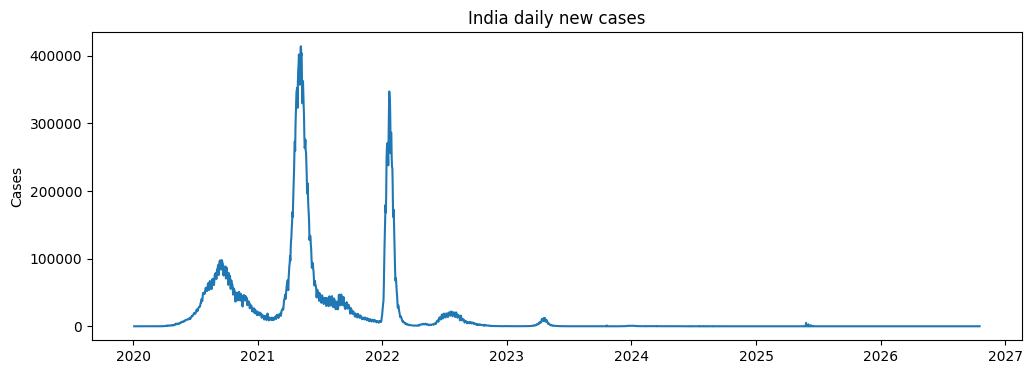

In [5]:
col = 'country' if 'country' in df.columns else 'location'
india = df[df[col] == 'India'].copy()
india['date'] = pd.to_datetime(india['date'])

print(india.shape)
print(india['date'].min(), india['date'].max())
print(india['new_cases'].isna().sum(), "missing values in new_cases")

plt.figure(figsize=(12, 4))
plt.plot(india['date'], india['new_cases'])
plt.title('India daily new cases')
plt.ylabel('Cases')
plt.show()

In [6]:
india = india.sort_values('date').reset_index(drop=True)

# 1. Kya data roz ka hai? Do dates ke beech ka gap dekho
gaps = india['date'].diff().dt.days
print(gaps.value_counts().head())

# 2. Negative ya zero values
print("Negative:", (india['new_cases'] < 0).sum())
print("Zero:", (india['new_cases'] == 0).sum())

# 3. Pehli kuch aur aakhri kuch rows
print(india[['date', 'new_cases']].head())
print(india[['date', 'new_cases']].tail())

date
1.0    2482
Name: count, dtype: int64
Negative: 0
Zero: 844
        date  new_cases
0 2020-01-01        NaN
1 2020-01-02        NaN
2 2020-01-03        NaN
3 2020-01-04        0.0
4 2020-01-05        0.0
           date  new_cases
2478 2026-10-14        0.0
2479 2026-10-15        0.0
2480 2026-10-16        0.0
2481 2026-10-17        0.0
2482 2026-10-18        0.0
